In [2]:
%load_ext autoreload
%autoreload 2

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from helper_functions import plot_gmm_results

In [5]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

In [16]:
preimputed_df = pd.read_parquet("eda_data/preimputed_data.parquet")
imputed_df = pd.read_parquet("eda_data/imputed_data.parquet")

## Skewness

In [17]:
skewness_df = pd.read_csv("eda_data/skewness.csv", index_col=0, names=['skewness'], header=0)
skewness_df.head()

,skewness
D1C,9.343611
commercial_places_within_1_mi,4.869575
rac_c000,2.103171
poverty_rate,1.701679
industrial_and_log_jobs_proportion,1.547458


In [22]:
def summarize_numeric_features(df):

    summary = pd.DataFrame({
        "pct_missing": df.isna().mean() * 100,
        "pct_zero": (df == 0).mean() * 100,
        "pct_one": (df==1).mean() * 100,
        "pct_mode": [df[col].value_counts(normalize=True, dropna=True).max() * 100 for col in df.columns],
        "mode": [df[col].value_counts(dropna=True).idxmax() if df[col].notna().any() else pd.NA for col in df.columns],
        "mean": df.mean(),
        "std": df.std(),
        "iqr": df.quantile(0.75) - df.quantile(0.25),
        "cv": (df.std()) / (df.mean().abs()),
        "n_unique": df.nunique()
    })

    return summary

summarize_numeric_features(imputed_df)

,pct_missing,pct_zero,pct_one,pct_mode,mode,mean,std,iqr,cv,n_unique
competitors_within_1_mi,0.0,4.475718,3.841274,4.475718,0.000000,44.379167,54.924394,61.000000,1.237617,243
median_household_income,0.0,0.000000,0.000000,10.185719,83359.000000,92906.058254,45722.956890,51094.000000,0.492142,3643
total_population,0.0,0.599839,0.000000,0.715192,994.000000,1068.006691,496.801039,611.000000,0.465167,1627
age_18_29_proportion,0.0,1.118930,0.046141,1.153536,0.177368,0.192004,0.112022,0.125855,0.583437,4280
poverty_rate,0.0,5.986850,0.000000,5.986850,0.000000,0.139702,0.137229,0.151550,0.982297,4065
bachelors_degree_proportion_25plus,0.0,1.453455,0.046141,1.453455,0.000000,0.205486,0.119002,0.155881,0.579126,4267
owner_occupied_proportion,0.0,4.890991,3.852809,4.890991,0.000000,0.548237,0.311450,0.543217,0.568093,3876
family_households_proportion,0.0,0.115354,0.761333,1.257354,0.631691,0.615598,0.189616,0.259363,0.308018,4169
no_vehicle_households_proportion,0.0,11.789134,0.726727,11.789134,0.000000,0.253912,0.275402,0.378509,1.084638,3624
D1C,0.0,0.126889,0.000000,18.364287,3.509165,23.387530,117.459828,7.186976,5.022327,3708


In [23]:
skewed_cols = skewness_df[skewness_df['skewness'].abs() >= 1].index

#for col in skewed_cols:
#    print(imputed_df[col].describe())
#    plt.figure(figsize=(7,4))
#    sns.histplot(imputed_df[col], bins=40)
#    plt.title(f"{col} | Skewness: {skewness_df.loc[col, 'skewness']:.2f}")
#    plt.tight_layout()
#    plt.show()

## GMM Evaluation

In [7]:
gmm_results_original = pd.read_csv("eda_data/gmm_results_original.csv")
gmm_results_five_pcs = pd.read_csv("eda_data/gmm_results_five_pcs.csv")
gmm_results_seven_pcs = pd.read_csv("eda_data/gmm_results_seven_pcs.csv")

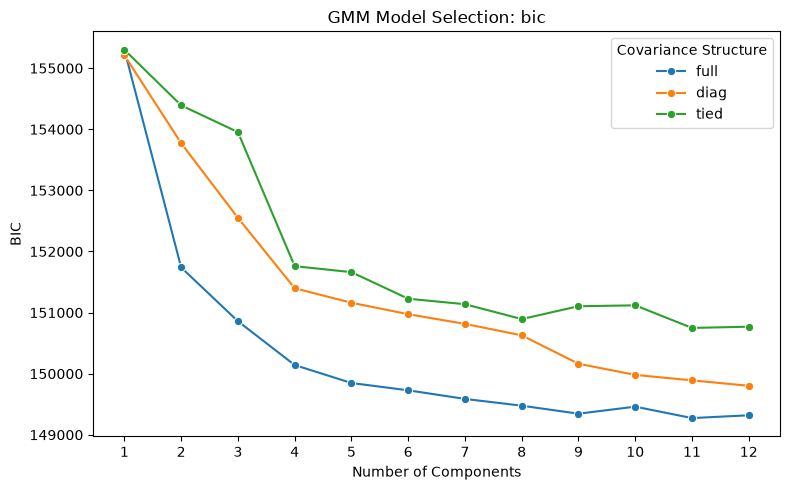

In [16]:
plot_gmm_results(gmm_results_five_pcs, metric='bic')

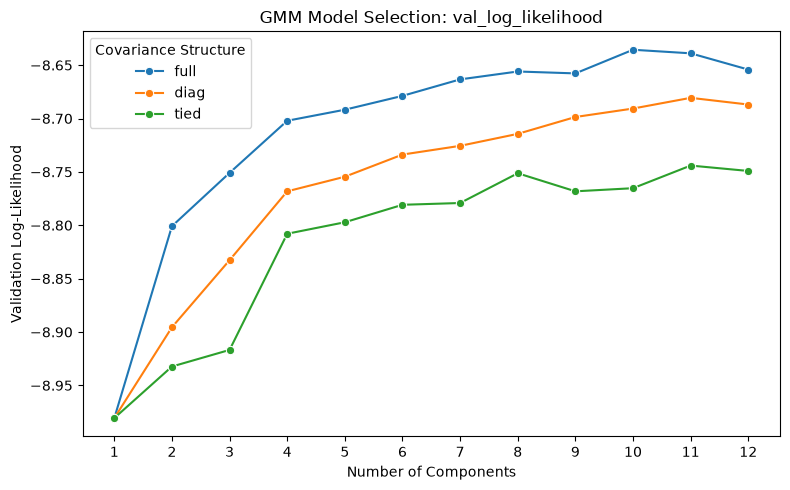

In [17]:
plot_gmm_results(gmm_results_five_pcs, metric='val_log_likelihood')

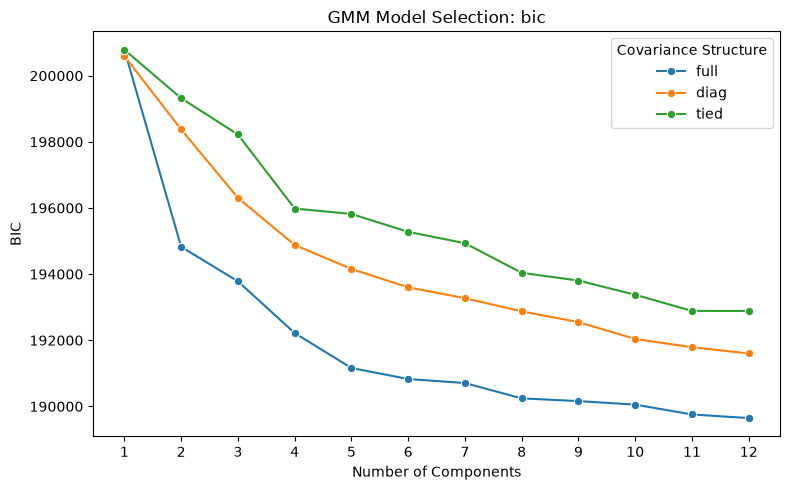

In [18]:
plot_gmm_results(gmm_results_seven_pcs, metric='bic')

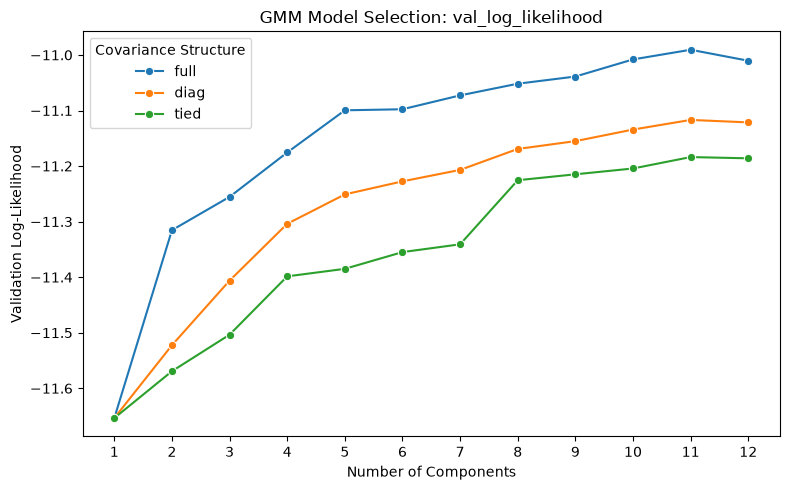

In [19]:
plot_gmm_results(gmm_results_seven_pcs, metric='val_log_likelihood')

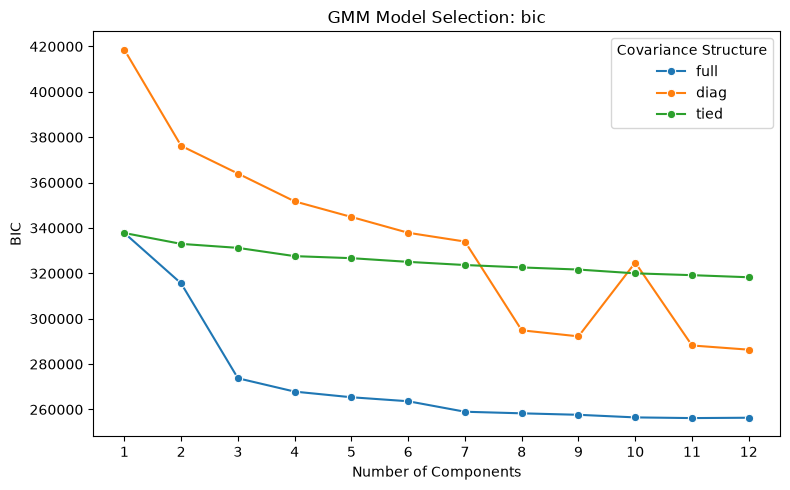

In [20]:
plot_gmm_results(gmm_results_original, metric='bic')

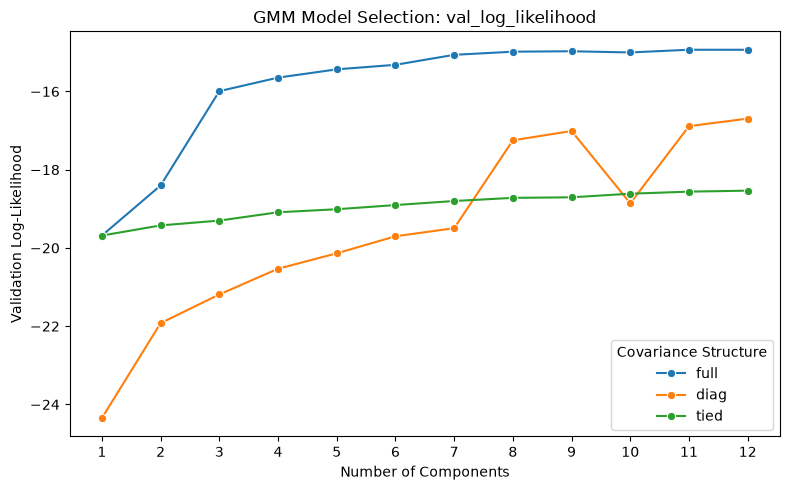

In [21]:
plot_gmm_results(gmm_results_original, metric='val_log_likelihood')